# MEDE U12 · CP4: structuri (clustering, anomalii) si comparatia aliniere orara vs. zilnica
**Unitate:** statie × zi (matricea zilnica) si statie × ora (matricea orara), Bucuresti, 2025

Intrari: `data/processed/X_features.csv` si `feature_dictionary.csv` (CP2), `hourly_aligned.csv` (CP1). Iesiri: `data/processed/` (tabele) si `figures/cp4_structuri.png`.
Rulare: *Restart & Run All* (cateva minute: matricea orara are ~25.000 de randuri).

**Ce face notebook-ul**
1. Construieste matricea **orara** (statie × ora) si o compara cu cea **zilnica** (statie × zi).
2. **Reducere de dimensionalitate** cu PCA (baseline din CP3, care a invins autoencoderul), cu metricile ei: varianta explicata, trustworthiness, pastrarea vecinilor kNN.
3. **Clustering** in spatiul redus (k-means si GMM), validat cu silhouette si stabilitate la bootstrap si la seed-uri.
4. **Anomalii** in spatiul redus: eroare de reconstructie, Isolation Forest, LOF.
5. **Comparatia orar vs. zilnic**: calitatea structurii, acordul dintre cele doua aliniri si anomaliile gasite.
6. **Ablatie pe k** (dimensiunea spatiului redus).

Descoperirea structurii este **exploratorie** (reducerea si clusterele se potrivesc pe toate randurile); garantia de robustete vine din bootstrap si din seed-uri. Performanta pe date nevazute a fost deja verificata la CP3.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score as ARI, normalized_mutual_info_score as NMI
from sklearn.manifold import trustworthiness
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, FIG = ROOT / "data" / "processed", ROOT / "figures"
FIG.mkdir(exist_ok=True)

SEEDS = [0, 1, 2, 3, 4]
NCL_RANGE = range(3, 9)     # numar de clustere testat (minimum 3, ca sa nu iasa o simpla impartire in 2)
B_BOOT = 30                 # reesantionari bootstrap
KDIMS = [2, 3, 4, 6, 8]     # ablatie pe dimensiunea spatiului redus
FLAG = 0.05                 # fractiunea de anomalii marcate de fiecare metoda
KNN = 10
N_SIL, N_TRUST = 4000, 3000 # subesantioane pentru metrici costisitoare pe matricea orara
LIMITS = (0, 500)           # QC poluanti (ca la CP2)
plt.rcParams.update({"figure.dpi": 130, "font.size": 8})
SEASON = {12: "iarna", 1: "iarna", 2: "iarna", 3: "primavara", 4: "primavara", 5: "primavara",
          6: "vara", 7: "vara", 8: "vara"}
season_of = lambda d: d.dt.month.map(SEASON).fillna("toamna")

## 1. Cele doua matrice
**Zilnica** (statie × zi) este matricea X de la CP2 (26 de trasaturi). **Orara** (statie × ora) pastreaza pasul de timp de o ora: valorile orare ale poluantilor si ale vremii, valorile de acum o ora, medii pe 3 ore, ora din zi (sin/cos) si weekend (13 trasaturi). La poluanti se aplica acelasi control de calitate ca la CP2 (valori in afara [0, 500] si zile cu valoare constanta devin NaN).

In [2]:
# --- matricea zilnica ---
X = pd.read_csv(PROC / "X_features.csv", parse_dates=["date"])
fd = pd.read_csv(PROC / "feature_dictionary.csv")
FEAT = fd.iloc[:, 0].tolist()
LOGD = fd.loc[fd["transformare"].str.startswith("log1p"), fd.columns[0]].tolist()

def prep(df, cols, logc):
    Z = df[cols].copy()
    c = [x for x in cols if x in logc]
    Z[c] = np.log1p(Z[c])
    return Z.values

Zd = StandardScaler().fit_transform(prep(X, FEAT, LOGD))
X["anotimp"] = season_of(X["date"])
print("zilnic:", Zd.shape)

zilnic: (1020, 26)


In [3]:
# --- matricea orara ---
hh = pd.read_csv(PROC / "hourly_aligned.csv", parse_dates=["time"]).sort_values(["station", "time"]).reset_index(drop=True)
hh["date"], hh["hour"] = hh["time"].dt.normalize(), hh["time"].dt.hour
qc = []
for p in ["NO2", "PM10"]:
    out = (hh[p] < LIMITS[0]) | (hh[p] > LIMITS[1])
    flat = hh.groupby(["station", "date"])[p].transform(lambda s: s.nunique() == 1 and s.count() >= 12).astype(bool)
    qc.append((p, int(out.sum()), int((flat & ~out).sum())))
    hh.loc[out | flat, p] = np.nan
print("QC (poluant, ore in afara intervalului, ore din zile constante):", qc)

g = hh.groupby("station")
for p in ["NO2", "PM10"]:
    hh[p + "_lag1"] = g[p].shift(1)
for c in ["NO2", "PM10", "W"]:
    hh[c + "_roll3"] = g[c].transform(lambda s: s.rolling(3, min_periods=3).mean())
hh["hour_sin"], hh["hour_cos"] = np.sin(2 * np.pi * hh["hour"] / 24), np.cos(2 * np.pi * hh["hour"] / 24)
hh["is_weekend"] = (hh["time"].dt.dayofweek >= 5).astype(int)
HF = ["NO2", "PM10", "T", "P", "W", "NO2_lag1", "PM10_lag1", "NO2_roll3", "PM10_roll3", "W_roll3",
      "hour_sin", "hour_cos", "is_weekend"]
H = hh.dropna(subset=HF).reset_index(drop=True)
sk = H[HF].skew()
LOGH = [c for c in HF if c not in ("hour_sin", "hour_cos", "is_weekend") and sk[c] > 1 and H[c].min() >= 0]
Zh = StandardScaler().fit_transform(prep(H, HF, LOGH))
H["anotimp"] = season_of(H["date"])
print("orar:", Zh.shape, "| log1p la:", LOGH)

QC (poluant, ore in afara intervalului, ore din zile constante): [('NO2', 0, 0), ('PM10', 168, 48)]
orar: (24957, 13) | log1p la: ['NO2', 'PM10', 'P', 'W', 'NO2_lag1', 'PM10_lag1', 'NO2_roll3', 'PM10_roll3', 'W_roll3']


## 2. Reducere de dimensionalitate (PCA) si metricile ei
Dimensiunea k se alege cu aceeasi regula pentru ambele aliniri: cel mai mic k care explica cel putin 80% din varianta. Metrici: **varianta explicata**, **trustworthiness** (10 vecini) si **pastrarea vecinilor kNN**, calculate pe un subesantion aleator (pentru matricea orara).

In [4]:
def choose_k(Z, thr=0.80):
    cum = PCA().fit(Z).explained_variance_ratio_.cumsum()
    return int(np.argmax(cum >= thr) + 1), cum

def knn_preservation(A, B, k=KNN):
    ia = NearestNeighbors(n_neighbors=k + 1).fit(A).kneighbors(A, return_distance=False)[:, 1:]
    ib = NearestNeighbors(n_neighbors=k + 1).fit(B).kneighbors(B, return_distance=False)[:, 1:]
    return np.mean([len(set(a) & set(b)) / k for a, b in zip(ia, ib)])

def reduction_metrics(Z, E, cum, k, seed=0):
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(Z), min(len(Z), N_TRUST), replace=False)
    return {"varianta_explicata": cum[k - 1],
            "trustworthiness": trustworthiness(Z[idx], E[idx], n_neighbors=KNN),
            "knn10_pastrare": knn_preservation(Z[idx], E[idx])}

ALIGN = {"zilnic": {"Z": Zd, "meta": X[["station", "date", "anotimp"]].copy()},
         "orar": {"Z": Zh, "meta": H[["station", "time", "date", "anotimp"]].copy()}}
for name, a in ALIGN.items():
    k, cum = choose_k(a["Z"])
    a["k"], a["cum"] = k, cum
    a["pca"] = PCA(n_components=k, random_state=0).fit(a["Z"])
    a["E"] = a["pca"].transform(a["Z"])
    a["red"] = reduction_metrics(a["Z"], a["E"], cum, k)
    print(name, "k =", k, {m: round(v, 3) for m, v in a["red"].items()})

zilnic k = 6 {'varianta_explicata': np.float64(0.82), 'trustworthiness': np.float64(0.987), 'knn10_pastrare': np.float64(0.571)}


orar k = 6 {'varianta_explicata': np.float64(0.864), 'trustworthiness': np.float64(0.995), 'knn10_pastrare': np.float64(0.699)}


## 3. Clustering in spatiul redus si validare
Numarul de clustere (3–8) se alege cu **silhouette** pe k-means. Validare: silhouette (medie ± std pe 5 seed-uri), **stabilitate la bootstrap** (k-means reantrenat pe 30 de reesantioane; se masoara acordul ARI cu partitia de referinta pe toate randurile) si stabilitate la seed-uri (ARI mediu intre partitiile a 5 seed-uri). GMM foloseste acelasi numar de clustere.

In [5]:
def sil(E, lab, seed=0):
    return silhouette_score(E, lab, sample_size=min(len(E), N_SIL), random_state=seed)

curves = {}
for name, a in ALIGN.items():
    E = a["E"]
    curves[name] = {n: sil(E, KMeans(n, n_init=10, random_state=0).fit_predict(E)) for n in NCL_RANGE}
    a["ncl"] = max(curves[name], key=curves[name].get)
    print(name, "silhouette pe numar de clustere:", {n: round(v, 3) for n, v in curves[name].items()}, "-> ales:", a["ncl"])

zilnic silhouette pe numar de clustere: {3: 0.2, 4: 0.182, 5: 0.189, 6: 0.191, 7: 0.192, 8: 0.179} -> ales: 3


orar silhouette pe numar de clustere: {3: 0.165, 4: 0.141, 5: 0.139, 6: 0.134, 7: 0.139, 8: 0.145} -> ales: 3


In [6]:
def bootstrap_ari(E, ref, ncl, B=B_BOOT, seed=0):
    rng = np.random.RandomState(seed)
    out = []
    for b in range(B):
        idx = rng.choice(len(E), len(E), replace=True)
        km = KMeans(ncl, n_init=3, random_state=b).fit(E[idx])
        out.append(ARI(ref, km.predict(E)))
    return np.array(out)

rows = []
for name, a in ALIGN.items():
    E, ncl = a["E"], a["ncl"]
    kms = [KMeans(ncl, n_init=10, random_state=s).fit_predict(E) for s in SEEDS]
    gms = [GaussianMixture(ncl, random_state=s).fit_predict(E) for s in SEEDS]
    a["km"], a["gm"] = kms[0], gms[0]
    sk_ = [sil(E, l, s) for l, s in zip(kms, SEEDS)]
    sg_ = [sil(E, l, s) for l, s in zip(gms, SEEDS)]
    boot = bootstrap_ari(E, a["km"], ncl)
    seed_ari = np.mean([ARI(kms[i], kms[j]) for i in range(5) for j in range(i + 1, 5)])
    a["boot"] = boot
    rows.append({"alinierea": name, "n_randuri": len(E), "k_dim": a["k"], **a["red"], "n_clustere": ncl,
                 "silhouette_kmeans": np.mean(sk_), "silhouette_kmeans_std": np.std(sk_),
                 "silhouette_gmm": np.mean(sg_), "silhouette_gmm_std": np.std(sg_),
                 "ARI_bootstrap": boot.mean(), "ARI_bootstrap_std": boot.std(), "ARI_seed": seed_ari,
                 "ARI_kmeans_gmm": ARI(a["km"], a["gm"]),
                 "NMI_anotimp": NMI(a["meta"]["anotimp"], a["km"]), "NMI_statie": NMI(a["meta"]["station"], a["km"]),
                 "NMI_ora_din_zi": NMI(a["meta"]["time"].dt.hour, a["km"]) if "time" in a["meta"] else np.nan})
main = pd.DataFrame(rows).set_index("alinierea")
main.round(3).T

alinierea,zilnic,orar
n_randuri,1020.000,24957.000
k_dim,6.000,6.000
varianta_explicata,0.820,0.864
trustworthiness,0.987,0.995
knn10_pastrare,0.571,0.699
n_clustere,3.000,3.000
silhouette_kmeans,0.200,0.163
silhouette_kmeans_std,0.000,0.002
silhouette_gmm,0.117,0.114
silhouette_gmm_std,0.006,0.002


## 4. Anomalii in spatiul redus
Trei metode: **eroarea de reconstructie** PCA, **Isolation Forest** si **LOF** (fiecare marcheaza 5% dintre randuri). Un rand este **anomalie de consens** daca e marcat de cel putin 2 din 3 metode.

In [7]:
def anomalies(Z, pca, E, seed=0, flag=FLAG):
    rec = ((Z - pca.inverse_transform(E)) ** 2).mean(axis=1)
    f_rec = rec >= np.quantile(rec, 1 - flag)
    f_if = IsolationForest(n_estimators=200, contamination=flag, random_state=seed).fit_predict(E) == -1
    f_lof = LocalOutlierFactor(n_neighbors=20, contamination=flag).fit_predict(E) == -1
    return pd.DataFrame({"anom_recon": f_rec, "anom_iforest": f_if, "anom_lof": f_lof,
                         "recon_err": rec}).assign(anom_consens=lambda d: d[["anom_recon", "anom_iforest", "anom_lof"]].sum(axis=1) >= 2)

jac = lambda a, b: (a & b).sum() / max((a | b).sum(), 1)
arows = []
for name, a in ALIGN.items():
    A_ = anomalies(a["Z"], a["pca"], a["E"])
    a["anom"] = A_
    arows.append({"alinierea": name, "recon": int(A_["anom_recon"].sum()), "iforest": int(A_["anom_iforest"].sum()),
                  "lof": int(A_["anom_lof"].sum()), "consens": int(A_["anom_consens"].sum()),
                  "Jaccard_recon_iforest": jac(A_["anom_recon"], A_["anom_iforest"]),
                  "Jaccard_recon_lof": jac(A_["anom_recon"], A_["anom_lof"]),
                  "Jaccard_iforest_lof": jac(A_["anom_iforest"], A_["anom_lof"])})
anom_tab = pd.DataFrame(arows).set_index("alinierea")
anom_tab.round(3).T

alinierea,zilnic,orar
recon,51.000,1248.000
iforest,51.000,1248.000
lof,51.000,1248.000
consens,37.000,734.000
Jaccard_recon_iforest,0.062,0.189
Jaccard_recon_lof,0.121,0.095
Jaccard_iforest_lof,0.457,0.144


## 5. Comparatia aliniere orara vs. zilnica
Cele doua matrice au unitati diferite (zi vs. ora), deci se compara la nivel de **zi**: fiecare zi primeste clusterul majoritar al orelor ei, iar anomaliile orare se agrega ca fractiune de ore anormale pe zi. Se raporteaza: acordul dintre partitii (ARI, NMI), cat de mult urmeaza fiecare partitie anotimpurile si statiile (NMI) si suprapunerea anomaliilor.

In [8]:
Hd = ALIGN["orar"]["meta"].copy()
Hd["cl_orar"] = ALIGN["orar"]["km"]
Hd["anom_h"] = ALIGN["orar"]["anom"]["anom_consens"].values
byday = Hd.groupby(["station", "date"]).agg(n_ore=("cl_orar", "size"),
                                            cl_orar_majoritar=("cl_orar", lambda s: s.value_counts().idxmax()),
                                            frac_ore_anormale=("anom_h", "mean")).reset_index()
byday = byday[byday["n_ore"] >= 12]

D = ALIGN["zilnic"]["meta"].copy()
D["cl_zilnic"] = ALIGN["zilnic"]["km"]
D["anom_z"] = ALIGN["zilnic"]["anom"]["anom_consens"].values
M_ = D.merge(byday, on=["station", "date"], how="inner")
n_anom = int(M_["anom_z"].sum())
top_h = M_["frac_ore_anormale"].rank(method="first", ascending=False) <= n_anom
agree = pd.DataFrame([{
    "zile_comune": len(M_),
    "ARI_zilnic_vs_orar": ARI(M_["cl_zilnic"], M_["cl_orar_majoritar"]),
    "NMI_zilnic_vs_orar": NMI(M_["cl_zilnic"], M_["cl_orar_majoritar"]),
    "NMI_anotimp_zilnic": NMI(M_["anotimp"], M_["cl_zilnic"]),
    "NMI_anotimp_orar": NMI(M_["anotimp"], M_["cl_orar_majoritar"]),
    "NMI_statie_zilnic": NMI(M_["station"], M_["cl_zilnic"]),
    "NMI_statie_orar": NMI(M_["station"], M_["cl_orar_majoritar"]),
    "anomalii_zilnice_consens": n_anom,
    "suprapunere_anomalii_(top_n_zile_orare)": int((M_["anom_z"] & top_h).sum()),
    "Jaccard_anomalii": jac(M_["anom_z"], top_h),
    "zile_cu_ore_anormale_>=25%": int((M_["frac_ore_anormale"] >= 0.25).sum())}])
agree.round(3).T

,0
zile_comune,1019.000
ARI_zilnic_vs_orar,0.217
NMI_zilnic_vs_orar,0.266
NMI_anotimp_zilnic,0.212
NMI_anotimp_orar,0.021
NMI_statie_zilnic,0.021
NMI_statie_orar,0.064
anomalii_zilnice_consens,37.000
suprapunere_anomalii_(top_n_zile_orare),11.000
Jaccard_anomalii,0.175


In [9]:
tab = main.copy()
tab["anomalii_consens"] = anom_tab["consens"]
tab["anomalii_consens_%"] = (100 * anom_tab["consens"] / main["n_randuri"]).round(1)
tab.round(3).to_csv(PROC / "table_main_alignment.csv")
agree.round(3).to_csv(PROC / "agreement_daily_vs_hourly.csv", index=False)
anom_tab.round(3).to_csv(PROC / "anomalies_summary.csv")
pd.DataFrame(curves).rename_axis("n_clustere").round(3).to_csv(PROC / "silhouette_vs_nclusters.csv")

# etichete pe zi (pentru interpretare la CP5 si exploratorul de la CP6)
cl = ALIGN["zilnic"]["meta"].copy()
cl["PC1"], cl["PC2"] = ALIGN["zilnic"]["E"][:, 0], ALIGN["zilnic"]["E"][:, 1]
cl["cluster_kmeans"], cl["cluster_gmm"] = ALIGN["zilnic"]["km"], ALIGN["zilnic"]["gm"]
cl = pd.concat([cl, ALIGN["zilnic"]["anom"]], axis=1)
cl = cl.merge(byday[["station", "date", "cl_orar_majoritar", "frac_ore_anormale"]], on=["station", "date"], how="left")
cl.round(4).to_csv(PROC / "clusters_daily.csv", index=False)

# profilul clusterelor zilnice
KEY = [c for c in ["NO2_mean", "PM10_mean", "T_mean", "T_range", "P_sum_3d", "W_mean", "W_calm_hours", "is_weekend"] if c in X.columns]
prof = X[KEY].assign(cluster=ALIGN["zilnic"]["km"]).groupby("cluster").mean()
prof.insert(0, "n_zile", pd.Series(ALIGN["zilnic"]["km"]).value_counts().sort_index())
for s in ["iarna", "primavara", "vara", "toamna"]:
    prof["%_" + s] = (X["anotimp"].eq(s).groupby(ALIGN["zilnic"]["km"]).mean() * 100)
for s in sorted(X["station"].unique()):
    prof["%_" + s] = (X["station"].eq(s).groupby(ALIGN["zilnic"]["km"]).mean() * 100)
prof.round(2).to_csv(PROC / "cluster_profiles_daily.csv")
prof.round(2)

,n_zile,NO2_mean,PM10_mean,T_mean,T_range,P_sum_3d,W_mean,W_calm_hours,is_weekend,%_iarna,%_primavara,%_vara,%_toamna,%_B-3,%_B-4,%_B-6
cluster,,,,,,,,,,,,,,,,
0,321,34.18,27.41,23.51,12.54,1.38,2.20,11.35,0.26,0.00,17.76,61.99,20.25,34.89,33.02,32.09
1,392,25.58,15.32,10.33,6.92,10.92,2.75,7.85,0.36,23.72,32.65,11.22,32.40,28.06,44.39,27.55
2,307,45.62,34.63,6.16,9.57,1.80,1.56,16.71,0.22,50.49,24.76,0.98,23.78,38.44,20.20,41.37


In [10]:
# profilul clusterelor orare: ce reprezinta ele?
kh = ALIGN["orar"]["km"]
hp = H[["NO2", "PM10", "T", "P", "W"]].groupby(kh).mean()
hp.insert(0, "n_ore", pd.Series(kh).value_counts().sort_index())
for s in ["iarna", "primavara", "vara", "toamna"]:
    hp["%_" + s] = H["anotimp"].eq(s).groupby(kh).mean() * 100
hp["ora_medie"] = H["hour"].groupby(kh).mean()
hp.round(2).to_csv(PROC / "cluster_profiles_hourly.csv")
hp.round(2)

,n_ore,NO2,PM10,T,P,W,%_iarna,%_primavara,%_vara,%_toamna,ora_medie
0,5115,21.08,8.63,12.01,0.26,3.32,18.49,32.55,16.95,32.00,11.06
1,10063,25.00,22.02,14.48,0.02,2.26,22.56,22.80,30.58,24.07,10.69
2,9779,51.19,36.53,12.65,0.02,1.61,29.27,24.71,21.63,24.40,12.70


## 6. Ablatie pe k (dimensiunea spatiului redus)
Se repeta reducerea, clusteringul (cu numarul de clustere ales mai sus) si stabilitatea pentru k = 2, 3, 4, 6, 8, pe fiecare aliniere.

In [11]:
abl = []
for name, a in ALIGN.items():
    cum_all = PCA().fit(a["Z"]).explained_variance_ratio_.cumsum()
    for kd in KDIMS:
        p = PCA(n_components=kd, random_state=0).fit(a["Z"]); E = p.transform(a["Z"])
        ref = KMeans(a["ncl"], n_init=10, random_state=0).fit_predict(E)
        boot = bootstrap_ari(E, ref, a["ncl"], B=15)
        abl.append({"alinierea": name, "k_dim": kd, "varianta_explicata": cum_all[kd - 1],
                    "trustworthiness": reduction_metrics(a["Z"], E, cum_all, kd)["trustworthiness"],
                    "silhouette": sil(E, ref), "ARI_bootstrap": boot.mean(), "ARI_bootstrap_std": boot.std()})
abl = pd.DataFrame(abl)
abl.round(3).to_csv(PROC / "ablation_k.csv", index=False)
abl.round(3)

,alinierea,k_dim,varianta_explicata,trustworthiness,silhouette,ARI_bootstrap,ARI_bootstrap_std
0,zilnic,2,0.527,0.855,0.354,0.853,0.133
1,zilnic,3,0.631,0.919,0.288,0.667,0.172
2,zilnic,4,0.716,0.958,0.244,0.647,0.189
3,zilnic,6,0.820,0.987,0.200,0.645,0.197
4,zilnic,8,0.888,0.996,0.182,0.577,0.177
5,orar,2,0.501,0.816,0.326,0.960,0.015
6,orar,3,0.622,0.894,0.258,0.821,0.138
7,orar,4,0.718,0.937,0.205,0.839,0.047
8,orar,6,0.864,0.995,0.165,0.798,0.117
9,orar,8,0.981,1.000,0.143,0.799,0.117


## 7. Figura pentru slide

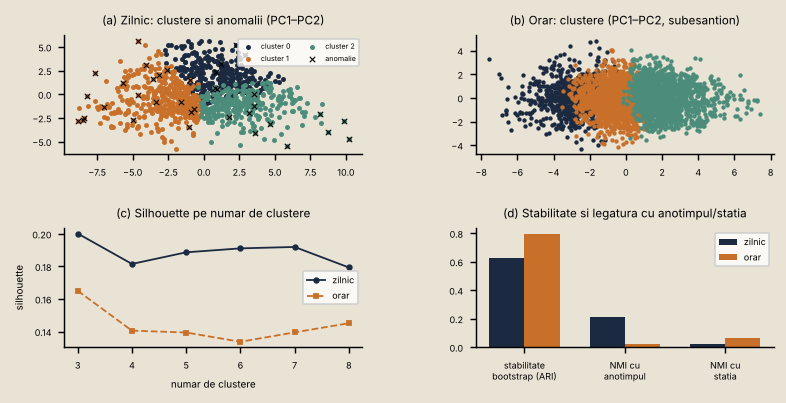

In [12]:
BG = "#E9E3D6"
COL = ["#1B2A41", "#C8702A", "#4C8C7A", "#8E6BA8", "#B5A642", "#7A7A7A", "#D1495B", "#2E86AB"]
fig, axes = plt.subplots(2, 2, figsize=(6.0, 3.0), facecolor=BG,
                         gridspec_kw=dict(wspace=0.38, hspace=0.62, left=0.075, right=0.985, top=0.92, bottom=0.12))
for a_ in axes.ravel(): a_.set_facecolor(BG); a_.tick_params(labelsize=5)
ax = axes[0, 0]
E, lab = ALIGN["zilnic"]["E"], ALIGN["zilnic"]["km"]
for c in range(ALIGN["zilnic"]["ncl"]):
    ax.scatter(E[lab == c, 0], E[lab == c, 1], s=3, color=COL[c], label=f"cluster {c}")
an = ALIGN["zilnic"]["anom"]["anom_consens"].values
ax.scatter(E[an, 0], E[an, 1], s=9, marker="x", color="black", lw=.6, label="anomalie")
ax.set_title("(a) Zilnic: clustere si anomalii (PC1–PC2)", fontsize=6.5); ax.legend(fontsize=4, ncol=2, loc="best")
ax = axes[0, 1]
rs = np.random.RandomState(0).choice(len(ALIGN["orar"]["E"]), 4000, replace=False)
E2, lab2 = ALIGN["orar"]["E"][rs], ALIGN["orar"]["km"][rs]
for c in range(ALIGN["orar"]["ncl"]):
    ax.scatter(E2[lab2 == c, 0], E2[lab2 == c, 1], s=2, color=COL[c])
ax.set_title("(b) Orar: clustere (PC1–PC2, subesantion)", fontsize=6.5)
ax = axes[1, 0]
for name, st in (("zilnic", "-o"), ("orar", "--s")):
    ax.plot(list(curves[name].keys()), list(curves[name].values()), st, ms=2.5, lw=1, label=name,
            color="#1B2A41" if name == "zilnic" else "#C8702A")
ax.set_xlabel("numar de clustere", fontsize=5.5); ax.set_ylabel("silhouette", fontsize=5.5)
ax.set_title("(c) Silhouette pe numar de clustere", fontsize=6.5); ax.legend(fontsize=5)
ax = axes[1, 1]
xx = np.arange(3); w = .35
vz = [main.loc["zilnic", "ARI_bootstrap"], agree["NMI_anotimp_zilnic"][0], agree["NMI_statie_zilnic"][0]]
vo = [main.loc["orar", "ARI_bootstrap"], agree["NMI_anotimp_orar"][0], agree["NMI_statie_orar"][0]]
ax.bar(xx - w / 2, vz, w, color="#1B2A41", label="zilnic"); ax.bar(xx + w / 2, vo, w, color="#C8702A", label="orar")
ax.set_xticks(xx); ax.set_xticklabels(["stabilitate\nbootstrap (ARI)", "NMI cu\nanotimpul", "NMI cu\nstatia"], fontsize=5)
ax.set_title("(d) Stabilitate si legatura cu anotimpul/statia", fontsize=6.5); ax.legend(fontsize=5)
for a_ in axes.ravel():
    for sp in ("top", "right"): a_.spines[sp].set_visible(False)
plt.savefig(FIG / "cp4_structuri.png", dpi=300, facecolor=BG); plt.show()

## 8. Verificari

In [13]:
for f in ["table_main_alignment.csv", "agreement_daily_vs_hourly.csv", "anomalies_summary.csv", "clusters_daily.csv",
          "cluster_profiles_daily.csv", "cluster_profiles_hourly.csv", "ablation_k.csv", "silhouette_vs_nclusters.csv"]:
    assert (PROC / f).exists(), f
assert np.isfinite(main.drop(columns="NMI_ora_din_zi").select_dtypes("number").values).all()
assert len(cl) == len(X)
print("OK")

OK
